In [49]:
# To increase the accuracy of the model. I increased the epoch to 50 from 25 to train the model more times and that is normally the highest you get wiithout getting diminishing returns. I also increased the window from 25 to 60 to give the model more past data to learn from in order to make a better prediction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [50]:
# Import csv file and set it as a dataframe
csv_path = "eth_hourly.csv"
df = pd.read_csv(csv_path)
df.head()

,Date,close,high,low,open,volume
0,2017-11-09,320.884003,329.451996,307.056000,308.644989,893249984
1,2017-11-10,299.252991,324.717987,294.541992,320.670990,885985984
2,2017-11-11,314.681000,319.453003,298.191986,298.585999,842300992
3,2017-11-12,307.907990,319.153015,298.513000,314.690002,1613479936
4,2017-11-13,316.716003,328.415009,307.024994,307.024994,1041889984


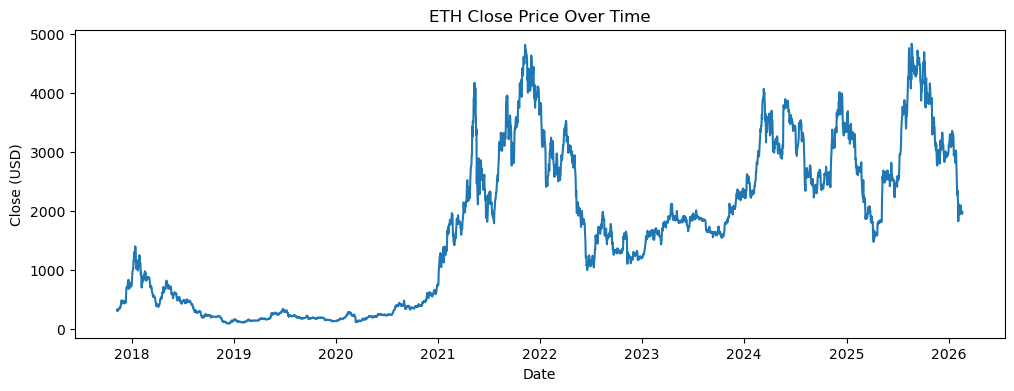

In [51]:
# Convert the Date column to a datetime object and sort the dataframe by date
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# Keep the target series (close)
series = df[["Date", "close"]].dropna()

# Plot the series
plt.figure(figsize=(12,4))
plt.plot(series["Date"], series["close"])
plt.title("ETH Close Price Over Time")
plt.xlabel("Date")
plt.ylabel("Close (USD)")
plt.show()

In [52]:
# Convert the close column to a numpy array
close_values = series["close"].values.reshape(-1, 1)

# Calculate the number of training, validation, and test samples
n = len(close_values)
train_end = int(n * 0.80)
val_end   = int(n * 0.85)

# Create training, validation, and test sets
train_raw = close_values[:train_end]
val_raw   = close_values[train_end:val_end]
test_raw  = close_values[val_end:]

# Scale the data
scaler = MinMaxScaler()
train = scaler.fit_transform(train_raw)
val   = scaler.transform(val_raw)
test  = scaler.transform(test_raw)

# Check the shape of the data
train.shape, val.shape, test.shape


((2420, 1), (152, 1), (454, 1))

In [53]:
# Gives historical data for the model to look at to make a better prediction
WINDOW = 60

# Creates a window of data for the model to look at to make a better prediction
def make_windows(data, window=60):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i])   # previous window days
        y.append(data[i])            # next day
    return np.array(X), np.array(y)

# Creates a window of data for the model to look at to make a better prediction
X_train, y_train = make_windows(train, WINDOW)
X_val,   y_val   = make_windows(val, WINDOW)
X_test,  y_test  = make_windows(test, WINDOW)

# Check the shape of the data
X_train.shape, y_train.shape


((2360, 60, 1), (2360, 1))

In [54]:
# Set the random seed for reproducibility
tf.random.set_seed(42)

# Create the model
model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(64),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

# Print the model summary
model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
# Early stopping to prevent overfitting
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=50,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0093 - mae: 0.0574 - val_loss: 0.0015 - val_mae: 0.0290
Epoch 2/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0020 - mae: 0.0269 - val_loss: 0.0027 - val_mae: 0.0409
Epoch 3/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0017 - mae: 0.0255 - val_loss: 0.0020 - val_mae: 0.0335
Epoch 4/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0016 - mae: 0.0245 - val_loss: 0.0019 - val_mae: 0.0324
Epoch 5/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0013 - mae: 0.0229 - val_loss: 0.0027 - val_mae: 0.0421
Epoch 6/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0013 - mae: 0.0225 - val_loss: 0.0020 - val_mae: 0.0344
Epoch 7/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0013 - mae: 0.0224 - val_loss: 0.0015 - val_mae: 0.0287
Epoch 8/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0011 - mae: 0.0211 - val_loss: 0.0018 - val_mae: 0.0330
Epoch 9/50
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0011 - mae: 

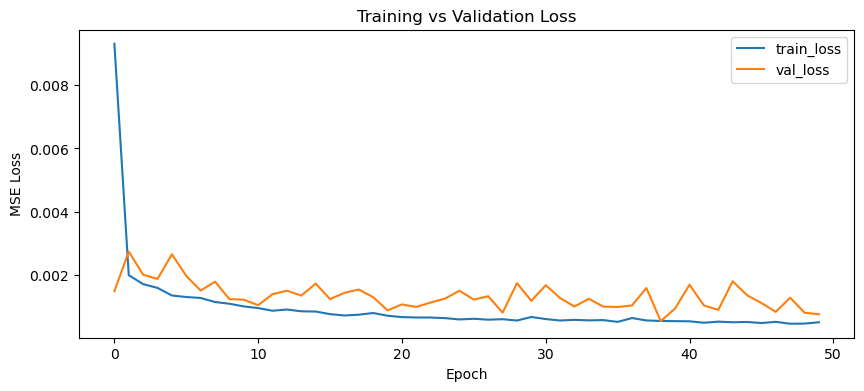

In [56]:
# Plot the training and validation loss

plt.figure(figsize=(10,4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [60]:
# Predict the test set
pred_test = model.predict(X_test)

# Inverse transform back to real USD prices
y_test_usd = scaler.inverse_transform(y_test)
pred_usd   = scaler.inverse_transform(pred_test)

# Calculate the MAE and RMSE
mae = mean_absolute_error(y_test_usd, pred_usd)
rmse = np.sqrt(mean_squared_error(y_test_usd, pred_usd))

print(f"Test MAE:  {mae:.2f} USD")
print(f"Test RMSE: {rmse:.2f} USD")


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Test MAE:  104.53 USD
Test RMSE: 142.85 USD


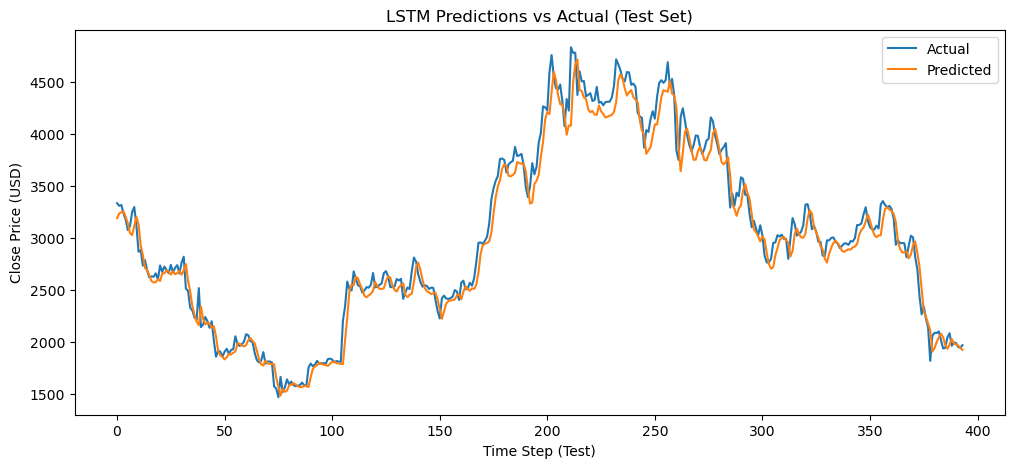

In [61]:
# Plot the predictions vs the actual values
plt.figure(figsize=(12,5))
plt.plot(y_test_usd, label="Actual")
plt.plot(pred_usd, label="Predicted")
plt.title("LSTM Predictions vs Actual (Test Set)")
plt.xlabel("Time Step (Test)")
plt.ylabel("Close Price (USD)")
plt.legend()
plt.show()


In [62]:
# Calculate MAPE (Mean Absolute Percentage Error)
mape = np.mean(np.abs((y_test_usd - pred_usd) / y_test_usd)) * 100
accuracy = 100 - mape

print(f"Test MAPE: {mape:.2f}%")
print(f"Accuracy:  {accuracy:.2f}%")

Test MAPE: 3.42%
Accuracy:  96.58%
